# Interactive dashboard (Appendix D)

Move the sliders to change bureaucratic friction $k$, the FDA subsidy $S_{pol}$ and the public
penalty $\gamma$. The other constants stay at their fitted values, and the trajectory from
(0.2, 0.2, 0.2) is recomputed over $0 \le t \le 100$ each time a slider moves. The title gives the
outcome class used in the paper: collapse if $x(100) \le 0.15$, stable ethics if $x(100) \ge 0.85$,
mixed otherwise.

Run all cells. The first one fits the model, which takes a few seconds.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import egt_core as egt

plt.rcParams.update({
    "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 8.5,
    "lines.linewidth": 1.6, "figure.dpi": 110, "savefig.dpi": 300,
    "axes.grid": True, "grid.alpha": 0.3, "axes.titleweight": "bold",
})

p = egt.P()                       # fitted constants
KBAR = egt.k_mean_historical()    # 0.7975, the 2010-2024 mean friction
TEXTW = 7.4                       # figure width used in the paper

In [2]:
def run_dashboard(k_bureaucracy=KBAR, S_pol=p["S_pol"], gamma=p["gamma"], ax=None, t_end=100, panel=""):
    t = np.linspace(0, t_end, 1000)
    s = egt.simulate((0.2, 0.2, 0.2), t, k=k_bureaucracy, S_pol=S_pol, gamma=gamma)
    own = ax is None
    if own: fig, ax = plt.subplots(figsize=(7, 3))
    ax.plot(t, s[:, 0], "b-", lw=2, label="ethical firms $x$"); ax.plot(t, s[:, 1], "r--", label="regulators $y$"); ax.plot(t, s[:, 2], "g:", lw=2, label="public $z$")
    xe = s[-1, 0]
    # labels used in the paper: at least 0.85 = stable, at most 0.15 = collapse, otherwise mixed
    status, col = (("Stable ethics", "darkgreen") if xe >= 0.85 else ("Collapse", "darkred") if xe <= 0.15 else (f"Mixed ($x$ = {xe:.2f})", "darkorange"))
    ax.set_title(f"{panel}{status}\n$k$ = {k_bureaucracy:.2f}, $S$ = {S_pol:.2f}, $\\gamma$ = {gamma:.2f}", color=col, fontsize=9)
    ax.set_xlabel("time $t$"); ax.set_ylabel("population share"); ax.set_ylim(-0.03, 1.03)
    if own: ax.legend(); plt.show()
    return xe

## Snapshot: Figure 19

The three example settings shown in the paper (collapse, mixed, stable ethics), drawn with the same
code as `egt_pharma_analysis.ipynb`. This output is saved in the notebook so it can be seen on GitHub.

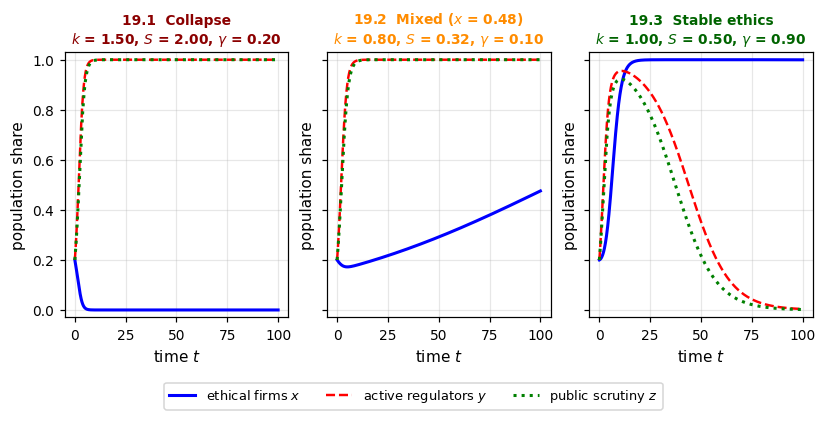

In [3]:
figD, axsD = plt.subplots(1, 3, figsize=(TEXTW, 3.3), sharey=True, constrained_layout=True)
for n_, (a, (kv, sv, gv)) in enumerate(zip(axsD, [(1.50, 2.00, 0.20), (0.80, 0.32, 0.10), (1.00, 0.50, 0.90)])):
    run_dashboard(kv, sv, gv, ax=a, panel=f"19.{n_ + 1}  ")
figD.legend(handles=[Line2D([], [], color="b", lw=2, label="ethical firms $x$"), Line2D([], [], color="r", ls="--", label="active regulators $y$"),
                     Line2D([], [], color="g", ls=":", lw=2, label="public scrutiny $z$")], loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=3, fontsize=8.5)
plt.show()

## Sliders

The sliders need a live Jupyter session (for example the mybinder link in the README); they do not
display on GitHub.

In [ ]:
from ipywidgets import interact, fixed, FloatSlider, Layout

# slider ranges cover all three outcomes
interact(run_dashboard,
         k_bureaucracy=FloatSlider(value=KBAR, min=0.0, max=1.5, step=0.05, description="friction k", layout=Layout(width="600px")),
         S_pol=FloatSlider(value=p["S_pol"], min=0.0, max=2.0, step=0.05, description="subsidy S", layout=Layout(width="600px")),
         gamma=FloatSlider(value=p["gamma"], min=0.0, max=2.0, step=0.05, description="public penalty", layout=Layout(width="600px")),
         ax=fixed(None), t_end=fixed(100), panel=fixed(""));